Лабораторна робота 2. Прізвище, група

[Текст ссылки](https://)# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [14]:
import numpy as np
import pandas as pd
import requests as req

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
html = req.get(url, headers= {"User-Agent": "Mozzila/5.0"}).text

tables = pd.read_html(html)
df = tables[2]
df.head(
)


/tmp/ipykernel_727/4039782197.py:8: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html)


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [15]:
df.shape


(222, 4)

 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [17]:
df.columns = df.columns.str.replace(r'\s*\[\d+\]+', '', regex=True)

df = df.rename(columns={'Country/Territory': 'Country'})

df


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211
...,...,...,...,...
217,Palau,377,345,310
218,Marshall Islands,342,308,281
219,Nauru,196,176,187
220,Montserrat,—N/a,—N/a,81


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [19]:
df.isna().sum()

,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


In [21]:
df['IMF (2026)'] = pd.to_numeric(df['IMF (2026)'], errors='coerce')
df['World Bank (2025)'] = pd.to_numeric(df['World Bank (2025)'], errors='coerce')
df['United Nations (2024)'] = pd.to_numeric(df['United Nations (2024)'], errors='coerce')

In [22]:
df.dtypes

,0
Country,object
IMF (2026),float64
World Bank (2025),float64
United Nations (2024),float64


In [23]:
df.isna().sum()

,0
Country,0
IMF (2026),31
World Bank (2025),35
United Nations (2024),9


In [34]:
df1 = df.fillna(df.mean(numeric_only=True))

df1

,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,World,1.262953e+08,1.183502e+08,111565144.0
1,United States,3.238392e+07,3.076970e+07,29298000.0
2,China[n 1],2.085159e+07,1.949804e+07,18743802.0
3,Germany,5.452858e+06,5.050923e+06,4659929.0
4,Japan,4.379253e+06,4.435163e+06,4026211.0
...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
219,Nauru,1.960000e+02,1.760000e+02,187.0
220,Montserrat,1.319229e+06,1.255590e+06,81.0


In [36]:
df1.isna().sum()

,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


5. Ще раз вивести датасет

6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [38]:
df1.duplicated().sum()

np.int64(0)

In [40]:
df1.drop_duplicates(inplace=True)

7.	Вивести описову статистику датасету describe()

In [ ]:
df1.describe

8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [43]:
df1['Difference'] = (df1['IMF (2026)'] - df1['World Bank (2025)']).abs()

df_sorted = df.sort_values(by='Difference', ascending=False)

df_sorted[['Country', 'IMF (2026)', 'World Bank (2025)', 'Difference']].head(10)

,Country,IMF (2026),World Bank (2025),Difference
0,World,126295331.0,118350166.0,7945165.0
1,United States,32383920.0,30769700.0,1614220.0
2,China[n 1],20851593.0,19498039.0,1353554.0
3,Germany,5452858.0,5050923.0,401935.0
10,Brazil,2635912.0,2279920.0,355992.0
12,Australia,2123963.0,1798519.0,325444.0
13,Mexico,2120855.0,1832641.0,288214.0
5,United Kingdom,4264794.0,4002588.0,262206.0
7,France,3596094.0,3366316.0,229778.0
6,India,4153191.0,3956067.0,197124.0


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [46]:
columns_to_correlate = ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']
correlation_matrix = df1[columns_to_correlate].corr()

correlation_matrix

,IMF (2026),World Bank (2025),United Nations (2024)
IMF (2026),1.000000,0.999497,0.998998
World Bank (2025),0.999497,1.000000,0.998864
United Nations (2024),0.998998,0.998864,1.000000


Обчислити середнє значення за стовпцями

In [ ]:
mean_values = df1.mean(numeric_only=True)

In [47]:
df1

,Country,IMF (2026),World Bank (2025),United Nations (2024),Difference
0,World,1.262953e+08,1.183502e+08,111565144.0,7.945165e+06
1,United States,3.238392e+07,3.076970e+07,29298000.0,1.614220e+06
2,China[n 1],2.085159e+07,1.949804e+07,18743802.0,1.353554e+06
3,Germany,5.452858e+06,5.050923e+06,4659929.0,4.019350e+05
4,Japan,4.379253e+06,4.435163e+06,4026211.0,5.591000e+04
...,...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0,3.200000e+01
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0,3.400000e+01
219,Nauru,1.960000e+02,1.760000e+02,187.0,2.000000e+01
220,Montserrat,1.319229e+06,1.255590e+06,81.0,6.363882e+04


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [50]:
numeric_cols = ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']

df1['Standard_Deviation'] = df1[numeric_cols].std(axis=1)

df_sorted_by_std = df.sort_values(by='Standard_Deviation', ascending=False)

df_sorted_by_std[['Country', 'Standard_Deviation']].head(5)

,Country,Standard_Deviation
0,World,7.372704e+06
1,United States,1.543508e+06
2,China[n 1],1.068002e+06
3,Germany,3.964771e+05
5,United Kingdom,2.898838e+05


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [53]:
columns_to_check = ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']

df_countries = df1[df1['Country'] != 'World']

for col in columns_to_check:
  max_row = df_countries.loc[df_countries[col].idxmax()]
  min_row = df_countries.loc[df_countries[col].idxmin()]

  print(f"Показник: {col}")
  print(f"Найвищий: {max_row['Country']} ({max_row[col]})")
  print(f"Найнижчий: {min_row['Country']} ({min_row[col]})")

Показник: IMF (2026)
Найвищий: United States (32383920.0)
Найнижчий: Tuvalu (65.0)
Показник: World Bank (2025)
Найвищий: United States (30769700.0)
Найнижчий: Tuvalu (57.0)
Показник: United Nations (2024)
Найвищий: United States (29298000.0)
Найнижчий: Tuvalu (56.0)


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

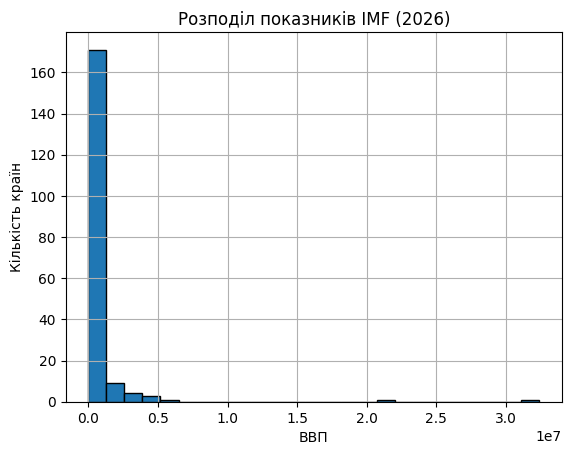

In [55]:
import matplotlib.pyplot as plt

df[df['Country'] != 'World']['IMF (2026)'].plot(
    kind='hist', bins=25, edgecolor='black', grid=True
)

plt.title('Розподіл показників IMF (2026)')
plt.xlabel('ВВП')
plt.ylabel('Кількість країн')
plt.show()

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [57]:
world_total = df.loc[df['Country'] == 'World', 'IMF (2026)'].values[0]

df['Share_IMF (%)'] = (df['IMF (2026)'] / world_total) * 100

print(df[['Country', 'Share_IMF (%)']].head())

         Country  Share_IMF (%)
0          World     100.000000
1  United States      25.641423
2     China[n 1]      16.510185
3        Germany       4.317545
4          Japan       3.467470


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

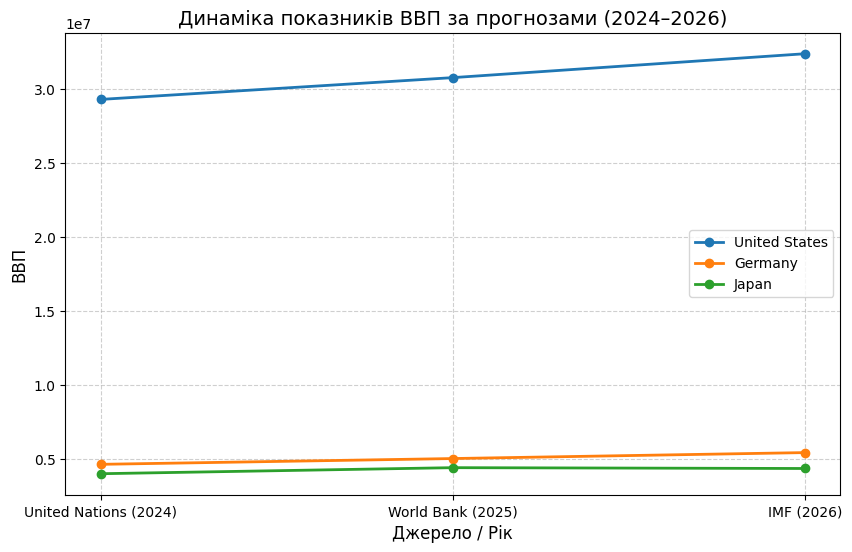

In [58]:
import matplotlib.pyplot as plt

countries_to_plot = ['United States', 'China', 'Germany', 'Japan']
df_subset = df[df['Country'].isin(countries_to_plot)]

years_cols = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']

plt.figure(figsize=(10, 6))

for _, row in df_subset.iterrows():
  plt.plot(
      years_cols,
      row[years_cols].values,
      marker='o',
      linewidth=2,
      label=row['Country'],
  )

plt.title(
    'Динаміка показників ВВП за прогнозами (2024–2026)',
    fontsize=14,
)
plt.xlabel('Джерело / Рік', fontsize=12)
plt.ylabel('ВВП', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()